# Fluxo experimental de classificação

## 1. Carregamento inicial
### 1.1 Importação das bibliotecas

Esta etapa verifica o arquivo, o esquema e a qualidade básica antes de qualquer modelagem. O objetivo é tornar explícito o que sabemos dos dados, não selecionar um modelo nem inferir significado clínico dos nomes codificados.

Coloque `final_treino_val.csv` em `data/raw/`. O arquivo é ignorado pelo Git. O regulamento define `desfecho=1` como classe positiva e `id` como identificador. Não use `id` como atributo preditor.

In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.ensemble import (
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

import json
import sklearn
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold



In [10]:
sns.set_theme(style="whitegrid")
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "final_treino_val.csv"
TARGET = "desfecho"
ID_COLUMN = "id"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Arquivo não encontrado: {DATA_PATH.resolve()}. "
        "Copie o CSV local para data/raw/ sem adicioná-lo ao Git."
    )

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip().str.lower()
df_dev, df_holdout = train_test_split(
    df, test_size=0.20, stratify=df[TARGET], random_state=42
)
print(f"Dimensões: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
print(f"Desenvolvimento: {len(df_dev):,}; holdout local reservado: {len(df_holdout):,}")
df_dev.head()

Dimensões: 6,332 linhas x 28 colunas
Desenvolvimento: 5,065; holdout local reservado: 1,267


,id,dadoclin1,dadoclin2,dadoclin3,dadoclin4,dadoclin5,dadoclin6,dadoclin7,dadoclin8,dadoclin9,...,sociodemografico4,sociodemografico5,comorbidade1,comorbidade2,comorbidade3,comorbidade4,comorbidade5,comorbidade6,comorbidade7,desfecho
2446,A512189,1,0,0,0,0,1,0,0,0,...,26,1,0,0,0,0,0,0,0,1
5074,A133781,0,0,0,0,0,1,0,0,1,...,9,4,0,0,0,0,0,0,0,1
3175,A575684,0,0,1,0,0,1,0,0,0,...,26,1,1,0,0,0,0,0,0,1
4463,A587360,1,0,1,0,0,1,0,0,0,...,26,1,0,0,0,0,0,0,0,0
1812,A022218,1,0,0,0,0,1,0,1,0,...,18,1,0,0,0,1,0,0,0,0


## 2. Preparação dos dados
### 2.1 Tratamento de inconsistências

Vamos confirmar a presença do identificador e do alvo, verificar os rótulos observados, valores ausentes, duplicatas e cardinalidade. Tipos inteiros, por si só, não significam que uma variável deva ser tratada como contínua; a classificação de tipos deve considerar o regulamento.

In [11]:
required_columns = {ID_COLUMN, TARGET}
missing_required = required_columns - set(df.columns)
if missing_required:
    raise ValueError(f"Colunas obrigatórias ausentes: {sorted(missing_required)}")

print("Tipos de dados:")
display(df.dtypes.rename("dtype").to_frame())

quality = pd.Series(
    {
        "linhas": len(df),
        "colunas": df.shape[1],
        "linhas duplicadas": int(df.duplicated().sum()),
        "IDs ausentes": int(df[ID_COLUMN].isna().sum()),
        "IDs duplicados": int(df[ID_COLUMN].duplicated().sum()),
        "alvos ausentes": int(df[TARGET].isna().sum()),
    },
)
display(quality.rename("valor").to_frame())
print("Valores ausentes por coluna:")
display(df.isna().sum().sort_values(ascending=False).rename("ausentes").to_frame())

observed_target = set(df[TARGET].dropna().unique())
if not observed_target.issubset({0, 1}):
    raise ValueError(f"Rótulos inesperados em {TARGET}: {observed_target}")
print("Rótulos observados:", sorted(observed_target))

Tipos de dados:


,dtype
id,str
dadoclin1,int64
dadoclin2,int64
dadoclin3,int64
dadoclin4,int64
dadoclin5,int64
dadoclin6,int64
dadoclin7,int64
dadoclin8,int64
dadoclin9,int64


,valor
linhas,6332
colunas,28
linhas duplicadas,0
IDs ausentes,0
IDs duplicados,0
alvos ausentes,0


Valores ausentes por coluna:


,ausentes
id,0
dadoclin1,0
dadoclin2,0
dadoclin3,0
dadoclin4,0
dadoclin5,0
dadoclin6,0
dadoclin7,0
dadoclin8,0
dadoclin9,0


Rótulos observados: [np.int64(0), np.int64(1)]


,valores distintos
dadoclin1,2
dadoclin2,2
dadoclin3,2
dadoclin4,2
dadoclin5,2
dadoclin6,2
dadoclin7,2
dadoclin8,2
dadoclin9,2
dadoclin10,2


,contagem,proporcao
desfecho,,
0,2166,0.427641
1,2899,0.572359


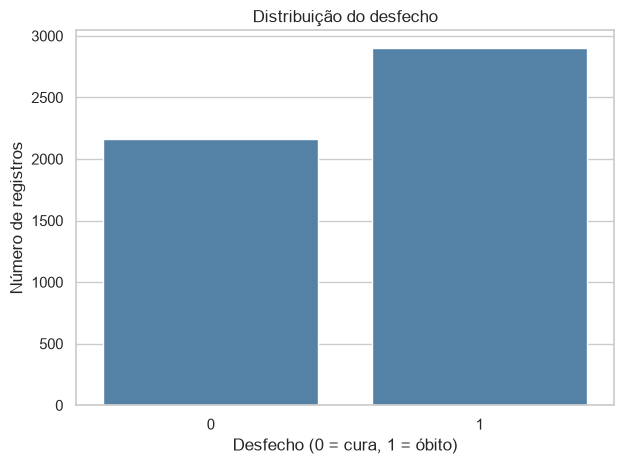

In [12]:
feature_columns = [c for c in df.columns if c not in {ID_COLUMN, TARGET}]
cardinality = df_dev[feature_columns].nunique(dropna=False).sort_values()
display(cardinality.rename("valores distintos").to_frame())

target_counts = df_dev[TARGET].value_counts(dropna=False).sort_index()
target_summary = pd.DataFrame(
    {"contagem": target_counts, "proporcao": target_counts / len(df_dev)}
)
display(target_summary)

ax = sns.countplot(data=df_dev, x=TARGET, order=[0, 1], color="steelblue")
ax.set(title="Distribuição do desfecho", xlabel="Desfecho (0 = cura, 1 = óbito)", ylabel="Número de registros")
plt.tight_layout()
plt.show()

### 2.2 Criação das variáveis

Esta etapa registra a cardinalidade e estatísticas descritivas sem atribuir significado clínico aos códigos. Neste primeiro ciclo, não criaremos variáveis derivadas: o significado das categorias não foi divulgado e engenharia de atributos deve ser motivada e avaliada dentro do protocolo.

Uma diferença observada entre grupos é descritiva e não demonstra causalidade. Nenhuma decisão de modelagem ou limiar deve ser tomada com base no conjunto de teste final.

In [13]:
display(df_dev[feature_columns].describe(include="all").T)

# Proporções do alvo por valor observado; útil para inspeção, sem interpretação causal.
for column in feature_columns:
    table = pd.crosstab(df_dev[column], df_dev[TARGET], normalize="index")
    table.columns = [f"proporcao_desfecho_{value}" for value in table.columns]
    print(f"{column} (n valores={df_dev[column].nunique(dropna=False)})")
    display(table)

,count,mean,std,min,25%,50%,75%,max
dadoclin1,5065.0,0.581046,0.493436,0.0,0.0,1.0,1.0,1.0
dadoclin2,5065.0,0.074235,0.262179,0.0,0.0,0.0,0.0,1.0
dadoclin3,5065.0,0.234748,0.423883,0.0,0.0,0.0,0.0,1.0
dadoclin4,5065.0,0.046594,0.210789,0.0,0.0,0.0,0.0,1.0
dadoclin5,5065.0,0.027443,0.163387,0.0,0.0,0.0,0.0,1.0
dadoclin6,5065.0,0.737414,0.440083,0.0,0.0,1.0,1.0,1.0
dadoclin7,5065.0,0.208292,0.406127,0.0,0.0,0.0,0.0,1.0
dadoclin8,5065.0,0.482132,0.499730,0.0,0.0,0.0,1.0,1.0
dadoclin9,5065.0,0.138203,0.345147,0.0,0.0,0.0,0.0,1.0
dadoclin10,5065.0,0.187364,0.390242,0.0,0.0,0.0,0.0,1.0


dadoclin1 (n valores=2)


,proporcao_desfecho_0,proporcao_desfecho_1
dadoclin1,,
0,0.359566,0.640434
1,0.476724,0.523276


dadoclin2 (n valores=2)


,proporcao_desfecho_0,proporcao_desfecho_1
dadoclin2,,
0,0.426104,0.573896
1,0.446809,0.553191


dadoclin3 (n valores=2)


... (43 outputs left out)

comorbidade6 (n valores=2)


,proporcao_desfecho_0,proporcao_desfecho_1
comorbidade6,,
0,0.467926,0.532074
1,0.272291,0.727709


comorbidade7 (n valores=2)


,proporcao_desfecho_0,proporcao_desfecho_1
comorbidade7,,
0,0.442223,0.557777
1,0.207006,0.792994


### 2.3 Pré-processamento

Para os modelos, as variáveis nominais serão codificadas com one-hot encoding e as quantitativas tratadas numericamente. Qualquer imputação, codificação ou escala será ajustada dentro de um `Pipeline`/`ColumnTransformer` durante cada fold, evitando que informação dos folds de validação influencie o pré-processamento. A auditoria atual não encontrou ausências, mas os imputadores permitem tratar ausências se surgirem. Este pré-processador ainda não foi ajustado; na etapa 4 ele será combinado com cada estimador em um `Pipeline`, para que cada fold aprenda as transformações apenas no próprio treino.



In [14]:
# Tipos definidos pelo regulamento e conferidos contra o esquema recebido.
binary_features = (
    [f"dadoclin{i}" for i in range(1, 15)]
    + ["sociodemografico1", "sociodemografico2"]
    + [f"comorbidade{i}" for i in range(1, 8)]
)
numeric_features = ["sociodemografico3"]
nominal_features = ["sociodemografico4", "sociodemografico5"]
expected_features = set(binary_features + numeric_features + nominal_features)
if set(feature_columns) != expected_features:
    raise ValueError("O esquema das variáveis preditoras difere do esperado; revisar antes de modelar.")

invalid_binary_values = {
    column: sorted(set(df[column].dropna().unique()) - {0, 1})
    for column in binary_features
    if not set(df[column].dropna().unique()).issubset({0, 1})
}
if invalid_binary_values:
    raise ValueError(f"Valores fora de 0/1 em variáveis binárias: {invalid_binary_values}")

binary_pipeline = SimpleImputer(strategy="most_frequent")
numeric_pipeline = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
)
nominal_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)
preprocessor = ColumnTransformer(
    transformers=[
        ("binary", binary_pipeline, binary_features),
        ("numeric", numeric_pipeline, numeric_features),
        ("nominal", nominal_pipeline, nominal_features),
    ],
    remainder="drop",
)
print("Pré-processador criado, ainda não ajustado.")


Pré-processador criado, ainda não ajustado.


## 3. Protocolo de avaliação

**Estratégia:** reservar uma partição estratificada de 20% como holdout final local, com `random_state=42`. Os 80% restantes serão usados para desenvolvimento e validação cruzada estratificada de 5 folds, com embaralhamento e semente fixa. A divisão é feita logo após o carregamento; as análises de relação entre atributos e alvo abaixo usam apenas o desenvolvimento.

**Seleção:** ROC-AUC média nos folds de validação (`scoring="roc_auc"`), coerente com a métrica principal do regulamento. O spot-check inicial usará configurações previamente definidas, sem busca extensa. Se houver ajuste posterior de hiperparâmetros, a CV será tratada como etapa de seleção. O holdout será usado ao final para avaliar o fluxo selecionado, não para escolher entre vários modelos.

**Métricas de avaliação:** ROC-AUC como critério principal; definir o limiar a partir de predições out-of-fold do desenvolvimento e então reportar sensibilidade, especificidade, LR−, F1 e matriz de confusão no holdout. AUC mede ordenação das probabilidades e não depende de limiar; LR− e F1 dependem.

**Prevenção de data leakage:** excluir `id` de `X`; separar holdout antes das análises de associação e de qualquer ajuste; combinar o pré-processador e cada estimador em um `Pipeline` e passar esse pipeline à validação cruzada, para ajustar transformações somente no treino de cada fold; não usar o teste oficial nem seus rótulos para decisões. Registros duplicados ou inconsistências serão investigados antes de qualquer remoção, sem descarte automático.

In [15]:
predictor_columns = binary_features + numeric_features + nominal_features
X_dev = df_dev[predictor_columns].copy()
X_holdout = df_holdout[predictor_columns].copy()
y_dev = df_dev[TARGET].astype(int).copy()
y_holdout = df_holdout[TARGET].astype(int).copy()
ids = df[ID_COLUMN].copy()  # Guardado à parte para rastreio e submissão.

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f"Desenvolvimento: {len(X_dev):,}; holdout local reservado: {len(X_holdout):,}")
print("Preditores:", X_dev.shape[1], "| identificador fora de X:", ID_COLUMN not in X_dev.columns)


Desenvolvimento: 5,065; holdout local reservado: 1,267
Preditores: 26 | identificador fora de X: True


## 4. Spot-checking dos algoritmos

### 4.1 Definição dos modelos e hiperparâmetros

Vamos comparar seis famílias em uma busca limitada e pré-definida: regressão logística como referência; Random Forest e Extra Trees para bagging; Gradient Boosting e HistGradientBoosting para boosting; e SVC com kernel RBF como método baseado em margem. Os ensembles de árvores e o SVC são candidatos capazes de capturar relações não lineares; essa é uma hipótese para experimentar, não uma garantia de melhor AUC.

A busca aleatória usa listas explícitas de valores, `scoring="roc_auc"` e semente fixa. Serão testadas 8 configurações em cada busca interna da validação aninhada e 15 na busca final em todo o desenvolvimento. O número de árvores fica fixo em 400 para Random Forest e Extra Trees, evitando gastar orçamento em um parâmetro cuja função principal é estabilizar o ensemble.

**Controle de overfitting:** a validação externa estratificada de 5 folds estima o desempenho de cada família; em cada fold externo, uma busca interna estratificada de 3 folds seleciona hiperparâmetros usando apenas o treino externo. Esse desenho separa seleção e avaliação e reduz o viés otimista de reportar a mesma CV usada para escolher hiperparâmetros. Depois, uma busca final ajusta os hiperparâmetros no conjunto de desenvolvimento inteiro. O holdout de 20% não participa de nenhuma busca.

In [16]:
models = {
    "logistic_regression": LogisticRegression(
        solver="lbfgs", l1_ratio=0.0, max_iter=3000, random_state=42
    ),
    "random_forest": RandomForestClassifier(
        n_estimators=400, random_state=42, n_jobs=1
    ),
    "extra_trees": ExtraTreesClassifier(
        n_estimators=400, random_state=42, n_jobs=1
    ),
    "gradient_boosting": GradientBoostingClassifier(random_state=42),
    "hist_gradient_boosting": HistGradientBoostingClassifier(
        random_state=42, early_stopping=False
    ),
    "svc_rbf": SVC(kernel="rbf"),
}

search_spaces = {
    "logistic_regression": {
        "model__C": [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0],
        "model__class_weight": [None, "balanced"],
    },
    "random_forest": {
        "model__max_depth": [None, 6, 10, 16],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4, 8, 16],
        "model__max_features": ["sqrt", 0.5, 0.8, 1.0],
        "model__class_weight": [None, "balanced_subsample"],
    },
    "extra_trees": {
        "model__max_depth": [None, 6, 10, 16],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4, 8, 16],
        "model__max_features": ["sqrt", 0.5, 0.8, 1.0],
        "model__class_weight": [None, "balanced"],
    },
    "gradient_boosting": {
        "model__n_estimators": [100, 200, 300],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [1, 2, 3],
        "model__min_samples_leaf": [5, 10, 20],
        "model__subsample": [0.7, 0.9, 1.0],
    },
    "hist_gradient_boosting": {
        "model__max_iter": [100, 200, 300, 500],
        "model__learning_rate": [0.03, 0.05, 0.08, 0.1],
        "model__max_leaf_nodes": [7, 15, 31],
        "model__min_samples_leaf": [10, 20, 30, 50],
        "model__l2_regularization": [0.0, 0.1, 1.0, 5.0],
    },
    "svc_rbf": {
        "model__C": [0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0],
        "model__gamma": ["scale", 0.001, 0.01, 0.1],
        "model__class_weight": [None, "balanced"],
    },
}

assert set(models) == set(search_spaces)
print(f"Famílias: {len(models)} | configurações por busca interna: 8 | busca final: 15")

Famílias: 6 | configurações por busca interna: 8 | busca final: 15


### 4.2 Execução dos algoritmos

Cada busca recebe uma `Pipeline` nova com o pré-processador. O `RandomizedSearchCV` clona e ajusta a pipeline dentro de cada fold, mantendo imputação, escala e one-hot encoding restritos ao treino daquele fold. A AUC externa é calculada em observações que não participaram nem do ajuste nem da escolha dos hiperparâmetros daquele fold.

A tabela de AUC aninhada é a comparação menos enviesada entre as famílias. A AUC da busca final nos dados de desenvolvimento serve apenas para escolher parâmetros e não deve ser apresentada como desempenho final. O SVC usa `decision_function` para calcular AUC; se for selecionado, a etapa de submissão deverá calibrar probabilidades usando apenas desenvolvimento. O holdout local permanece reservado para avaliar a solução escolhida.

In [17]:
N_ITER_NESTED = 8
N_ITER_FINAL = 15
INNER_SPLITS = 3
outer_cv = cv  # 5 folds estratificados, random_state=42, definidos no protocolo.

nested_scores = {name: [] for name in models}
nested_fold_params = {name: [] for name in models}

for model_name, model in models.items():
    print(f"Validação aninhada: {model_name}", flush=True)
    for fold_number, (train_idx, valid_idx) in enumerate(outer_cv.split(X_dev, y_dev), start=1):
        X_outer_train = X_dev.iloc[train_idx]
        y_outer_train = y_dev.iloc[train_idx]
        X_outer_valid = X_dev.iloc[valid_idx]
        y_outer_valid = y_dev.iloc[valid_idx]

        inner_cv = StratifiedKFold(
            n_splits=INNER_SPLITS, shuffle=True, random_state=100 + fold_number
        )
        pipeline = Pipeline(
            steps=[("preprocessor", clone(preprocessor)), ("model", clone(model))]
        )
        search = RandomizedSearchCV(
            estimator=pipeline,
            param_distributions=search_spaces[model_name],
            n_iter=N_ITER_NESTED,
            scoring="roc_auc",
            cv=inner_cv,
            refit=True,
            random_state=42 + fold_number,
            n_jobs=-1,
            error_score="raise",
            return_train_score=False,
        )
        search.fit(X_outer_train, y_outer_train)

        fitted = search.best_estimator_
        if hasattr(fitted, "predict_proba"):
            outer_scores = fitted.predict_proba(X_outer_valid)[:, 1]
        else:
            outer_scores = fitted.decision_function(X_outer_valid)
        nested_scores[model_name].append(
            float(roc_auc_score(y_outer_valid, outer_scores))
        )
        nested_fold_params[model_name].append(
            {key: value.item() if hasattr(value, "item") else value
             for key, value in search.best_params_.items()}
        )
        print(f"  fold {fold_number}: AUC externa={nested_scores[model_name][-1]:.4f}", flush=True)

nested_summary = pd.DataFrame(
    [
        {
            "modelo": name,
            "auc_externa_media": np.mean(scores),
            "auc_externa_dp": np.std(scores, ddof=1),
            "auc_por_fold": scores,
        }
        for name, scores in nested_scores.items()
    ]
).sort_values("auc_externa_media", ascending=False).reset_index(drop=True)

display(nested_summary)

# Busca final dos hiperparâmetros em todo o desenvolvimento; o holdout não é usado.
final_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
final_searches = {}
for model_name, model in models.items():
    print(f"Busca final no desenvolvimento: {model_name}", flush=True)
    pipeline = Pipeline(
        steps=[("preprocessor", clone(preprocessor)), ("model", clone(model))]
    )
    final_search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=search_spaces[model_name],
        n_iter=N_ITER_FINAL,
        scoring="roc_auc",
        cv=final_cv,
        refit=True,
        random_state=2026,
        n_jobs=-1,
        error_score="raise",
        return_train_score=False,
    )
    final_search.fit(X_dev, y_dev)
    final_searches[model_name] = final_search
    print(f"  melhor AUC de seleção CV={final_search.best_score_:.4f}", flush=True)

stage4_results = {
    "protocol": {
        "scikit_learn_version": sklearn.__version__,
        "positive_class": 1,
        "selection_metric": "roc_auc",
        "outer_cv": {"type": "StratifiedKFold", "n_splits": 5, "shuffle": True, "random_state": 42},
        "inner_cv": {"type": "StratifiedKFold", "n_splits": INNER_SPLITS, "shuffle": True, "random_state": "100 + outer fold"},
        "nested_random_search_iterations_per_fold": N_ITER_NESTED,
        "final_development_search_iterations": N_ITER_FINAL,
        "development_rows": int(len(X_dev)),
        "holdout_reserved_rows": int(len(X_holdout)),
        "holdout_used_for_model_selection_or_scoring": False,
        "preprocessing_inside_pipeline": True,
    },
    "nested_cv": {
        name: {
            "outer_auc_by_fold": scores,
            "outer_auc_mean": float(np.mean(scores)),
            "outer_auc_std": float(np.std(scores, ddof=1)),
            "best_params_by_outer_fold": nested_fold_params[name],
        }
        for name, scores in nested_scores.items()
    },
    "best_params_on_full_development": {
        name: {
            "best_cv_auc_for_selection_only": float(search.best_score_),
            "best_params": {
                key: value.item() if hasattr(value, "item") else value
                for key, value in search.best_params_.items()
            },
        }
        for name, search in final_searches.items()
    },
    "search_spaces": search_spaces,
}

RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)
RESULTS_PATH = RESULTS_DIR / "stage4_model_search.json"
RESULTS_PATH.write_text(
    json.dumps(stage4_results, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(f"Resultados e hiperparâmetros salvos em: {RESULTS_PATH}")

Validação aninhada: logistic_regression
  fold 1: AUC externa=0.7392
  fold 2: AUC externa=0.7398
  fold 3: AUC externa=0.7267
  fold 4: AUC externa=0.7540
  fold 5: AUC externa=0.7298
Validação aninhada: random_forest
  fold 1: AUC externa=0.7397
  fold 2: AUC externa=0.7413
  fold 3: AUC externa=0.7301
  fold 4: AUC externa=0.7659
  fold 5: AUC externa=0.7385
Validação aninhada: extra_trees
  fold 1: AUC externa=0.7331
  fold 2: AUC externa=0.7272
  fold 3: AUC externa=0.7253
  fold 4: AUC externa=0.7671
  fold 5: AUC externa=0.7308
Validação aninhada: gradient_boosting
  fold 1: AUC externa=0.7376
  fold 2: AUC externa=0.7417
  fold 3: AUC externa=0.7347
  fold 4: AUC externa=0.7599
  fold 5: AUC externa=0.7357
Validação aninhada: hist_gradient_boosting
  fold 1: AUC externa=0.7381
  fold 2: AUC externa=0.7405
  fold 3: AUC externa=0.7332
  fold 4: AUC externa=0.7619
  fold 5: AUC externa=0.7369
Validação aninhada: svc_rbf
  fold 1: AUC externa=0.7363
  fold 2: AUC externa=0.7382
  

,modelo,auc_externa_media,auc_externa_dp,auc_por_fold
0,random_forest,0.743088,0.013459,"[0.739659, 0.7413, 0.730083, 0.765884, 0.738517]"
1,hist_gradient_boosting,0.742111,0.011374,"[0.738114, 0.740531, 0.733161, 0.761892, 0.736..."
2,gradient_boosting,0.741930,0.010416,"[0.737589, 0.741746, 0.734714, 0.759927, 0.735..."
3,svc_rbf,0.737908,0.010416,"[0.736318, 0.73819, 0.728303, 0.755188, 0.731541]"
4,logistic_regression,0.737906,0.010694,"[0.739245, 0.739763, 0.72669, 0.754046, 0.729786]"
5,extra_trees,0.736692,0.017252,"[0.733139, 0.727156, 0.72534, 0.76707, 0.730753]"


Busca final no desenvolvimento: logistic_regression
  melhor AUC de seleção CV=0.7384
Busca final no desenvolvimento: random_forest
  melhor AUC de seleção CV=0.7425
Busca final no desenvolvimento: extra_trees
  melhor AUC de seleção CV=0.7380
Busca final no desenvolvimento: gradient_boosting
  melhor AUC de seleção CV=0.7440
Busca final no desenvolvimento: hist_gradient_boosting
  melhor AUC de seleção CV=0.7421
Busca final no desenvolvimento: svc_rbf
  melhor AUC de seleção CV=0.7399
Resultados e hiperparâmetros salvos em: c:\Users\Eduardo\Documents\GitHub\hospital-mortality-prediction\results\stage4_model_search.json


## Próxima etapa

### 5. Resultados
#### 5.1 Tabela comparativa
Apresentar médias e dispersões da AUC externa aninhada. Depois das decisões de modelo, avaliar uma única solução selecionada no holdout local reservado.

#### 5.2 Gráfico comparativo
Visualizar ROC-AUC por modelo com dispersão entre folds e escala adequada, sem atribuir superioridade a diferenças pequenas sem contexto.

### 6. Interpretação dos resultados
#### 6.1 Modelos mais promissores
Identificar os modelos mais promissores segundo o protocolo e comparar a estimativa aninhada com a avaliação independente no holdout.

#### 6.2 Padrões e diferenças
Descrever diferenças e comportamentos relevantes entre os modelos e a estabilidade dos hiperparâmetros entre folds.

#### 6.3 O que os resultados sugerem
Discutir o que os resultados sugerem sobre a tarefa e os dados, com cautela associativa e sem afirmações causais.